# 05 – Visualisation and findings

This notebook produces every **chart and table for the report**. It needs no new data collection.

| Input | From |
|---|---|
| `data/grab_sentiment_clean.csv` | final clean, labelled posts (2,015) |
| `result/01_model_comparison.csv` | notebook 06 (model comparison) |

**Outputs:** charts go to `outputs/figures/fig01-fig08_*.png` and `fig11_*.png` (300 dpi, ready for Word), tables go to `outputs/tables/tab01-tab11_*.csv`, `tab14_*.csv` and `tab15_*.csv`, and the appendix file to `outputs/appendix_grab_posts_2015.csv`.
The written findings for the report are in **`outputs/FINDINGS.md`**.

All the code is in `src/findings.py`. This notebook only runs it and shows the results.

In [1]:
import sys, os, pandas as pd
from pathlib import Path
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 200)
from src.findings import run, TOPICS

r = run()
T = r["tables"]
print(f"{len(r['figures'])} figures and {len(T)} tables written.")
show = lambda name: display(Image(f"outputs/figures/{name}.png", width=760))

9 figures and 13 tables written.


## 1. The dataset

In [2]:
display(T["tab01_dataset_overview"])

lang_group,platform,English,Malay,Mixed (Manglish),Total,earliest_post,latest_post,pct_comments
0,Total,1348,530,137,2015,2025-11-07,2026-11-17,57.2
1,X (Twitter),519,421,93,1033,2025-11-07,2026-11-17,39.8
2,Reddit,666,4,6,676,2025-11-09,2026-10-26,88.2
3,Threads,137,53,34,224,2026-01-25,2026-11-17,28.1
4,TikTok,17,30,4,51,2026-09-05,2026-11-17,100.0
5,Facebook,9,22,0,31,2026-02-25,2026-11-16,100.0


## 2. Overall sentiment
Negative and neutral posts are equally common (about 45% each). Only about 1 post in 9 is positive.

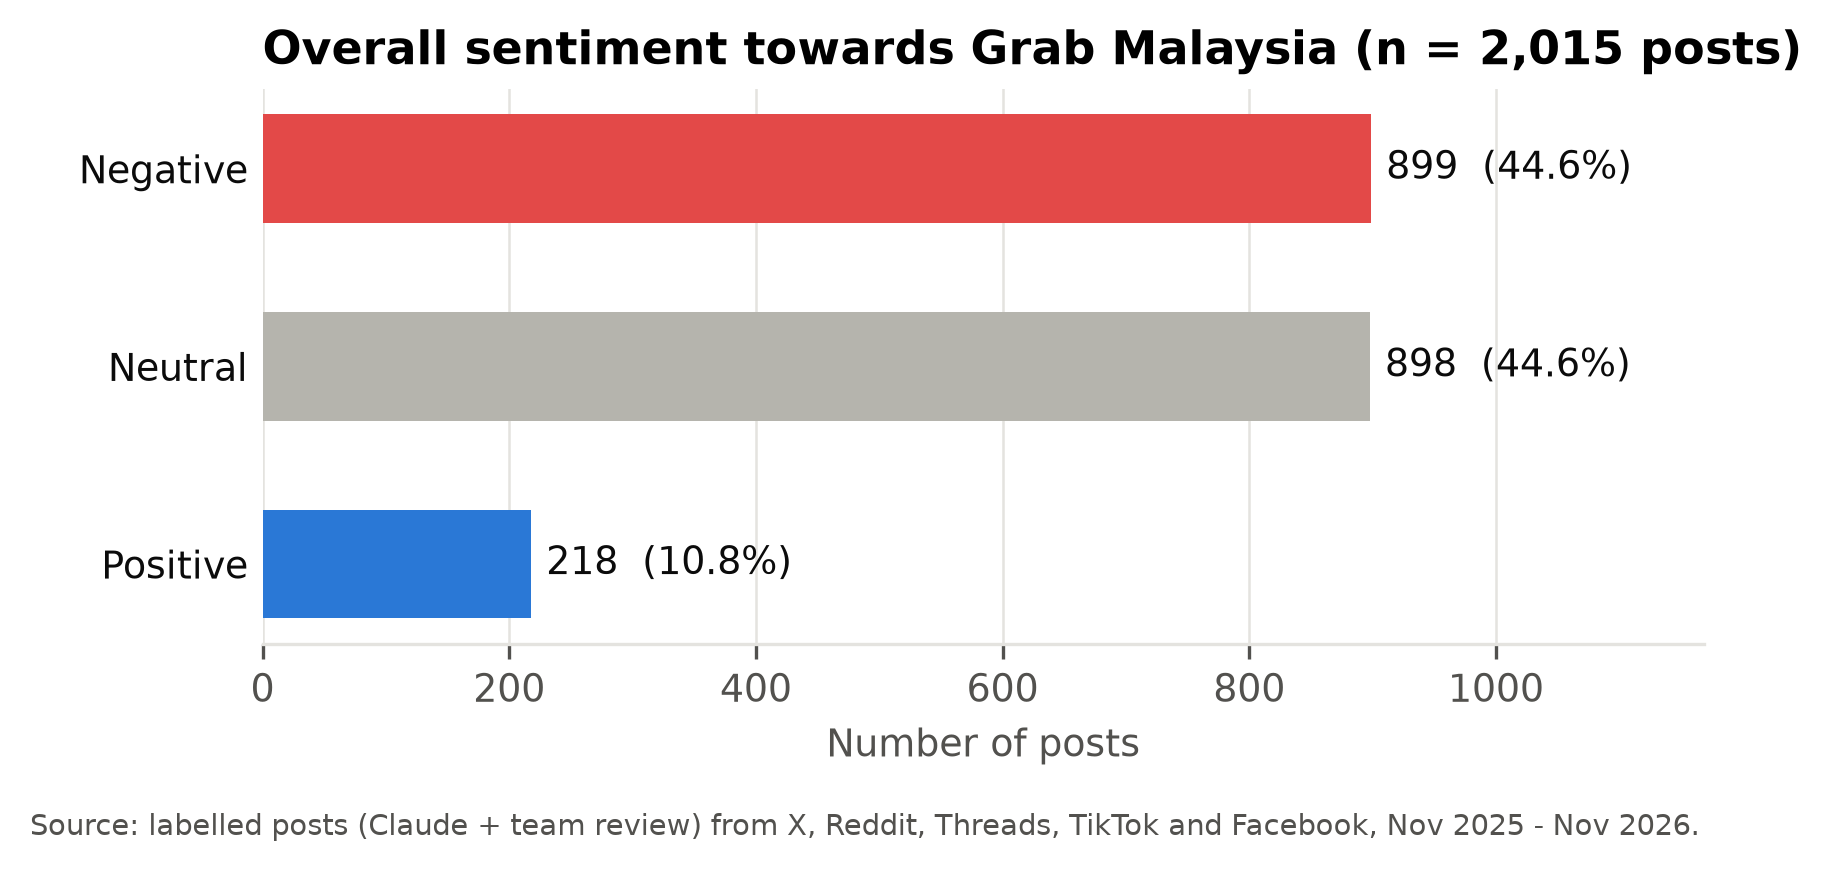

In [3]:
show("fig01_sentiment_overall")

## 3. Sentiment by platform and by language
Threads, Facebook and TikTok look much more negative. Most of their posts are **replies or comments addressed to Grab's own account**, where people go to complain.
Section 6 tests this directly.

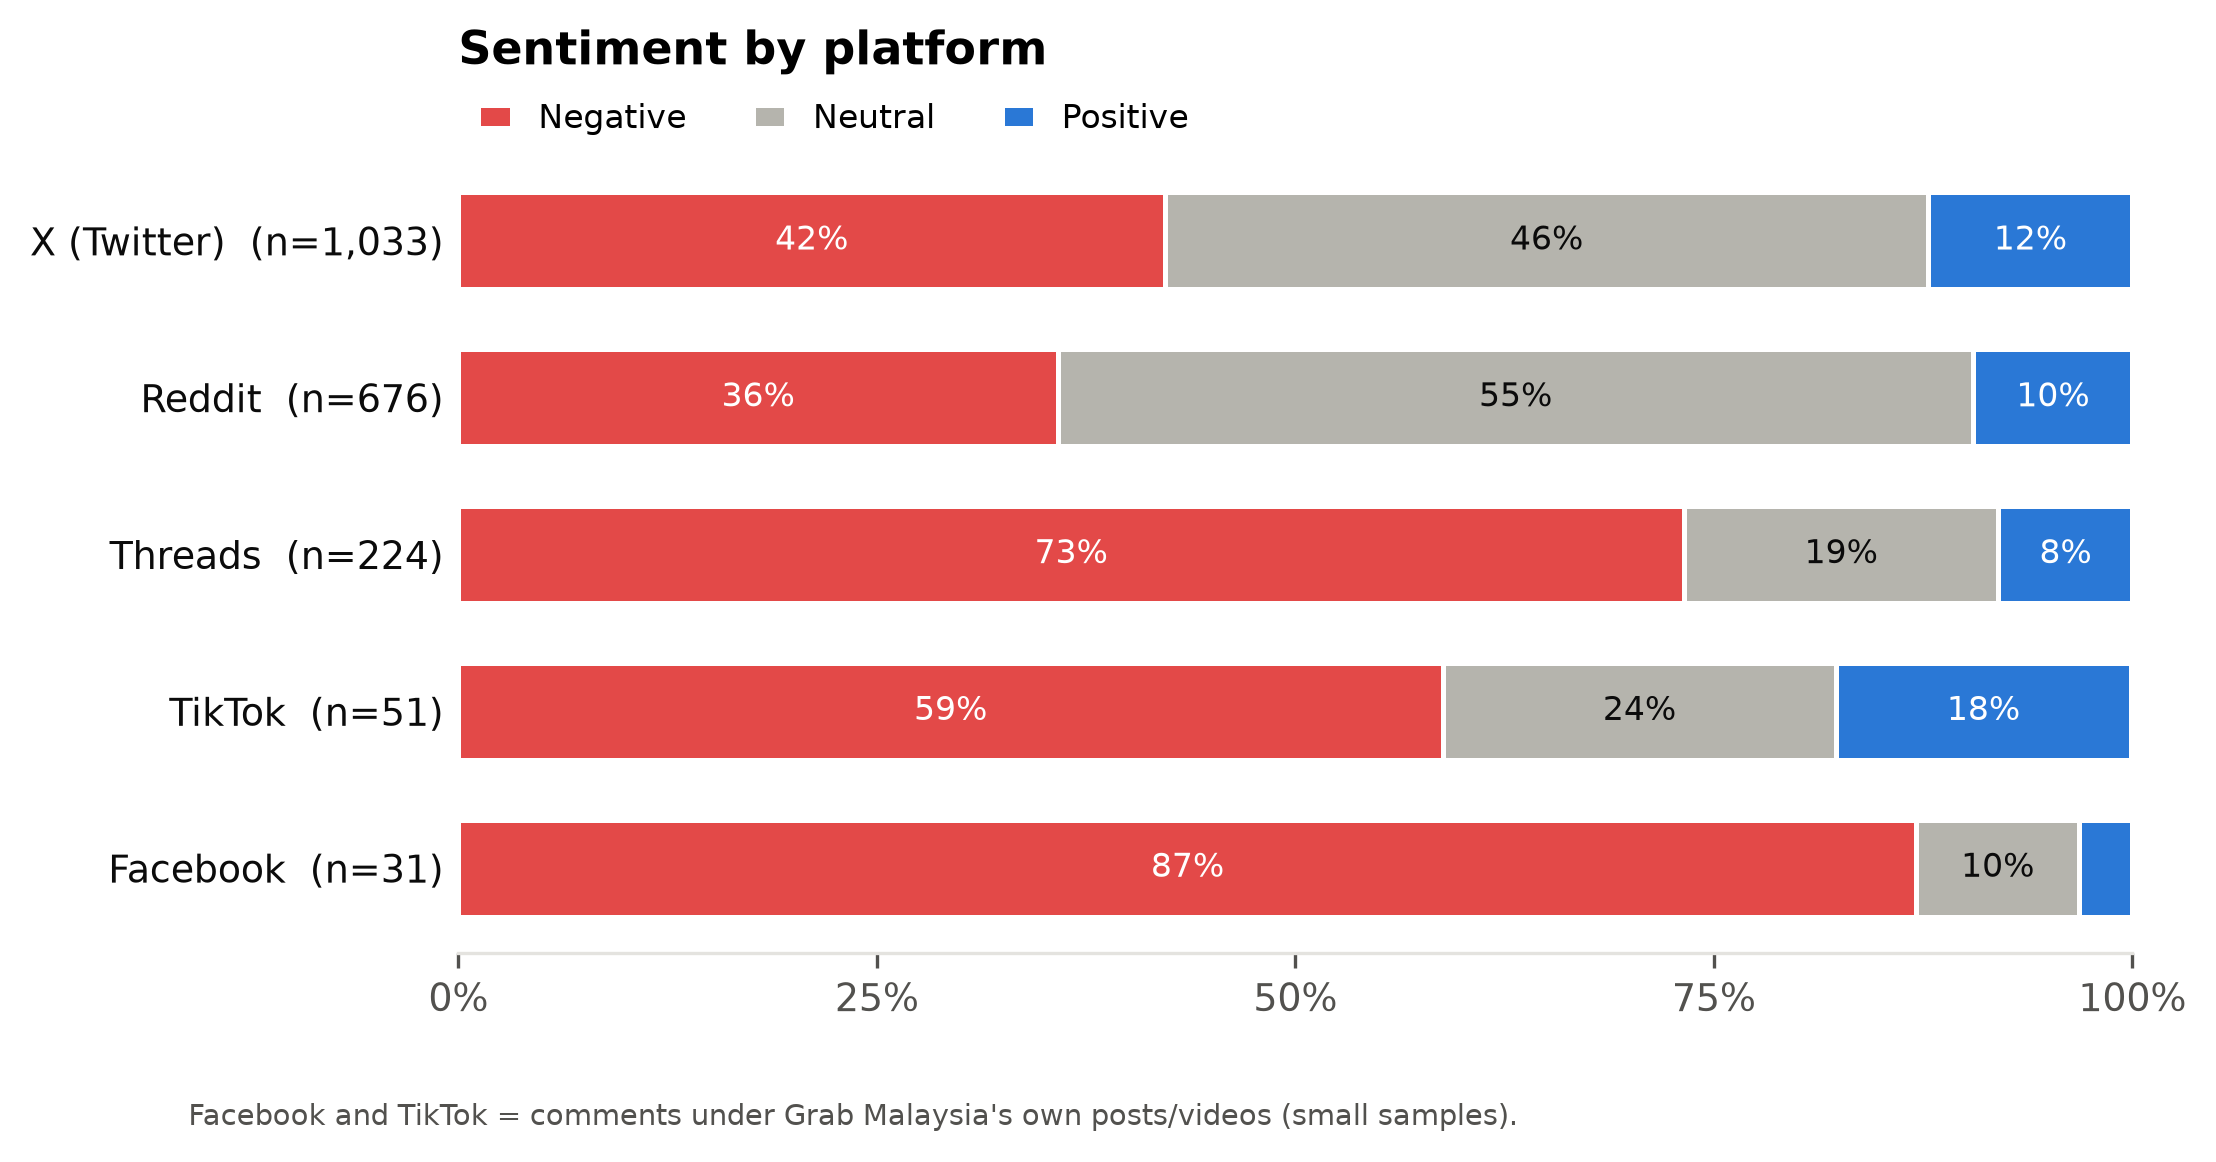

,platform,n_posts,n_negative,n_neutral,n_positive,pct_negative,pct_neutral,pct_positive,net_sentiment
0,X (Twitter),1033,436,471,126,42.2,45.6,12.2,-30.0
1,Reddit,676,242,370,64,35.8,54.7,9.5,-26.3
2,Threads,224,164,42,18,73.2,18.8,8.0,-65.2
3,TikTok,51,30,12,9,58.8,23.5,17.6,-41.2
4,Facebook,31,27,3,1,87.1,9.7,3.2,-83.9
5,All posts,2015,899,898,218,44.6,44.6,10.8,-33.8


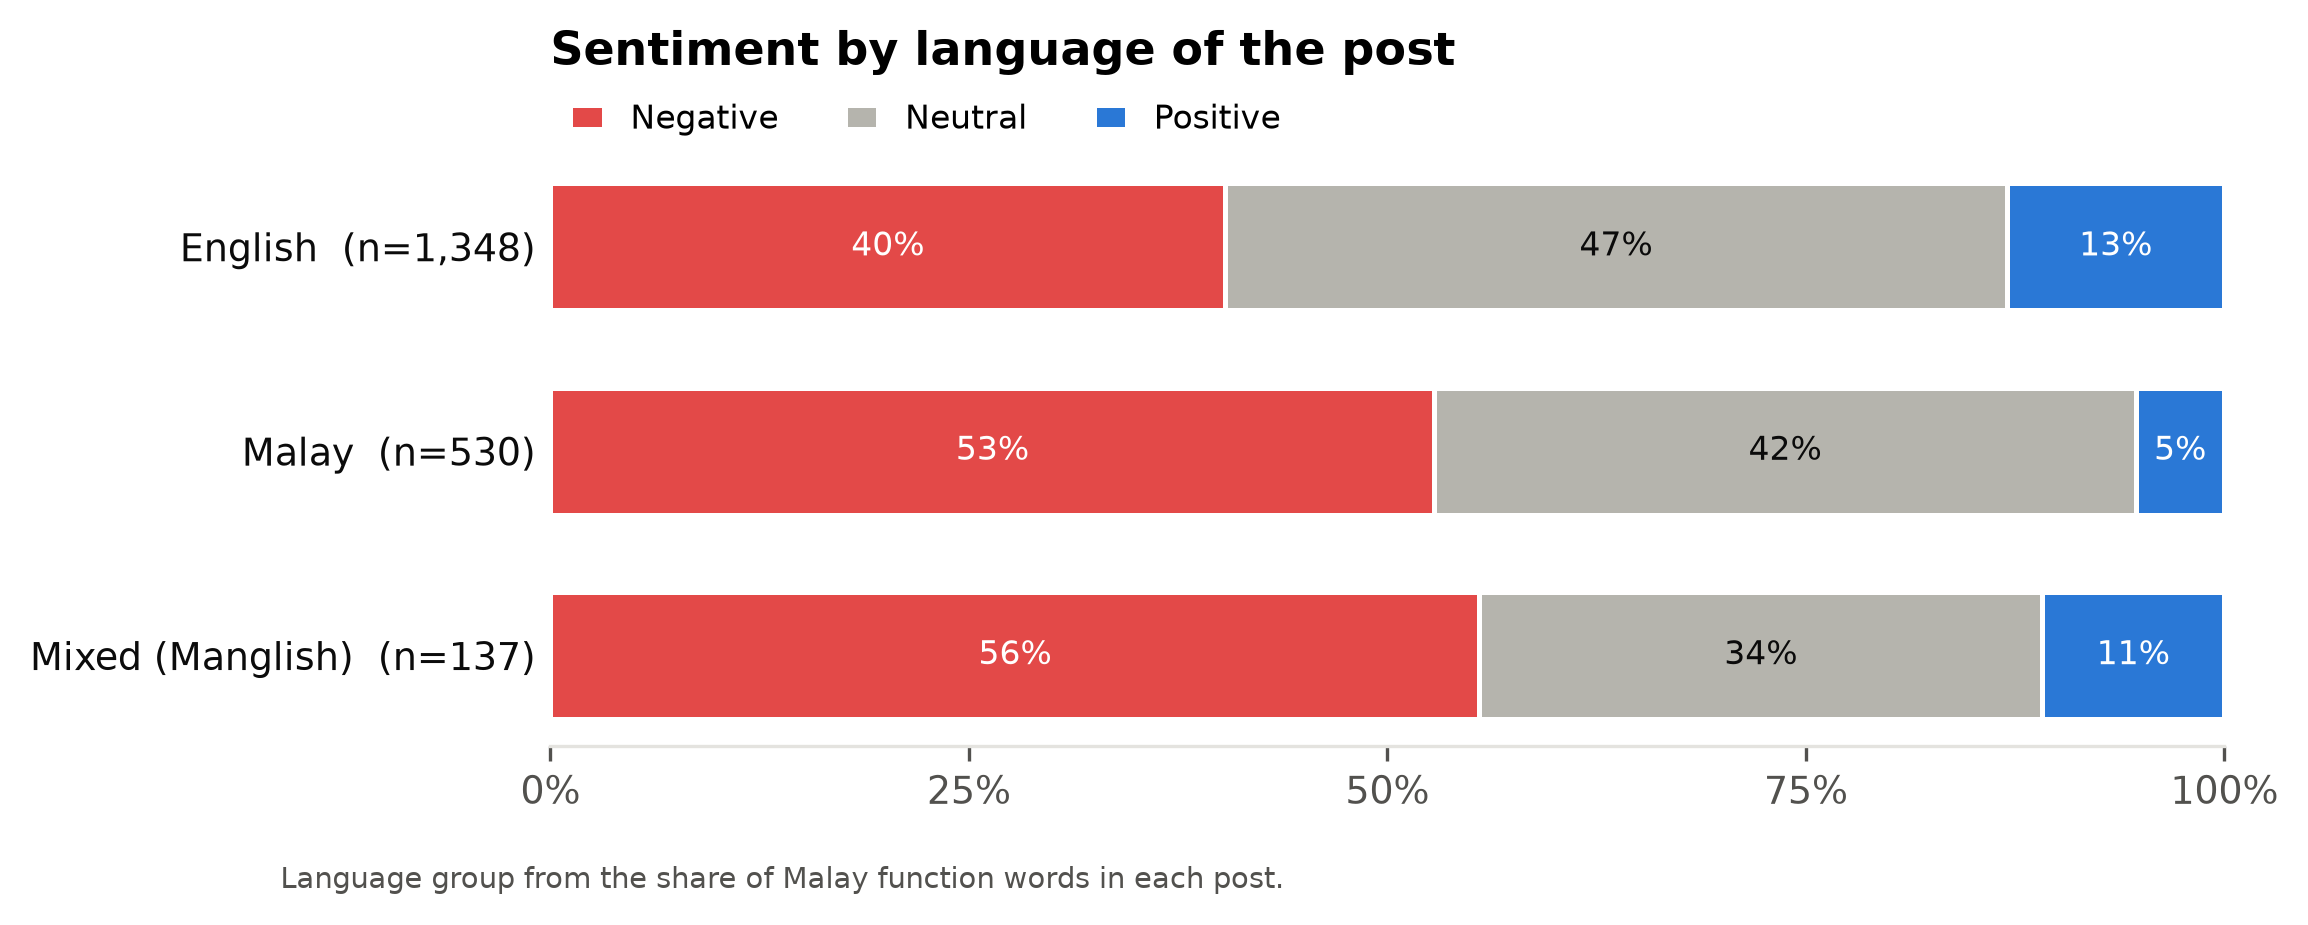

,lang_group,n_posts,n_negative,n_neutral,n_positive,pct_negative,pct_neutral,pct_positive,net_sentiment
0,English,1348,543,630,175,40.3,46.7,13.0,-27.3
1,Malay,530,280,222,28,52.8,41.9,5.3,-47.5
2,Mixed (Manglish),137,76,46,15,55.5,33.6,10.9,-44.5
3,All posts,2015,899,898,218,44.6,44.6,10.8,-33.8


In [4]:
show("fig02_sentiment_by_platform"); display(T["tab02_sentiment_by_platform"])
show("fig03_sentiment_by_language"); display(T["tab03_sentiment_by_language"])

## 4. Sentiment over time
Read this chart with care. **November 2026 includes the extra Threads collection of customer posts answered by @GrabMY** (mostly complaints), so it is more negative and not comparable with the other months. The chart caption says this too.

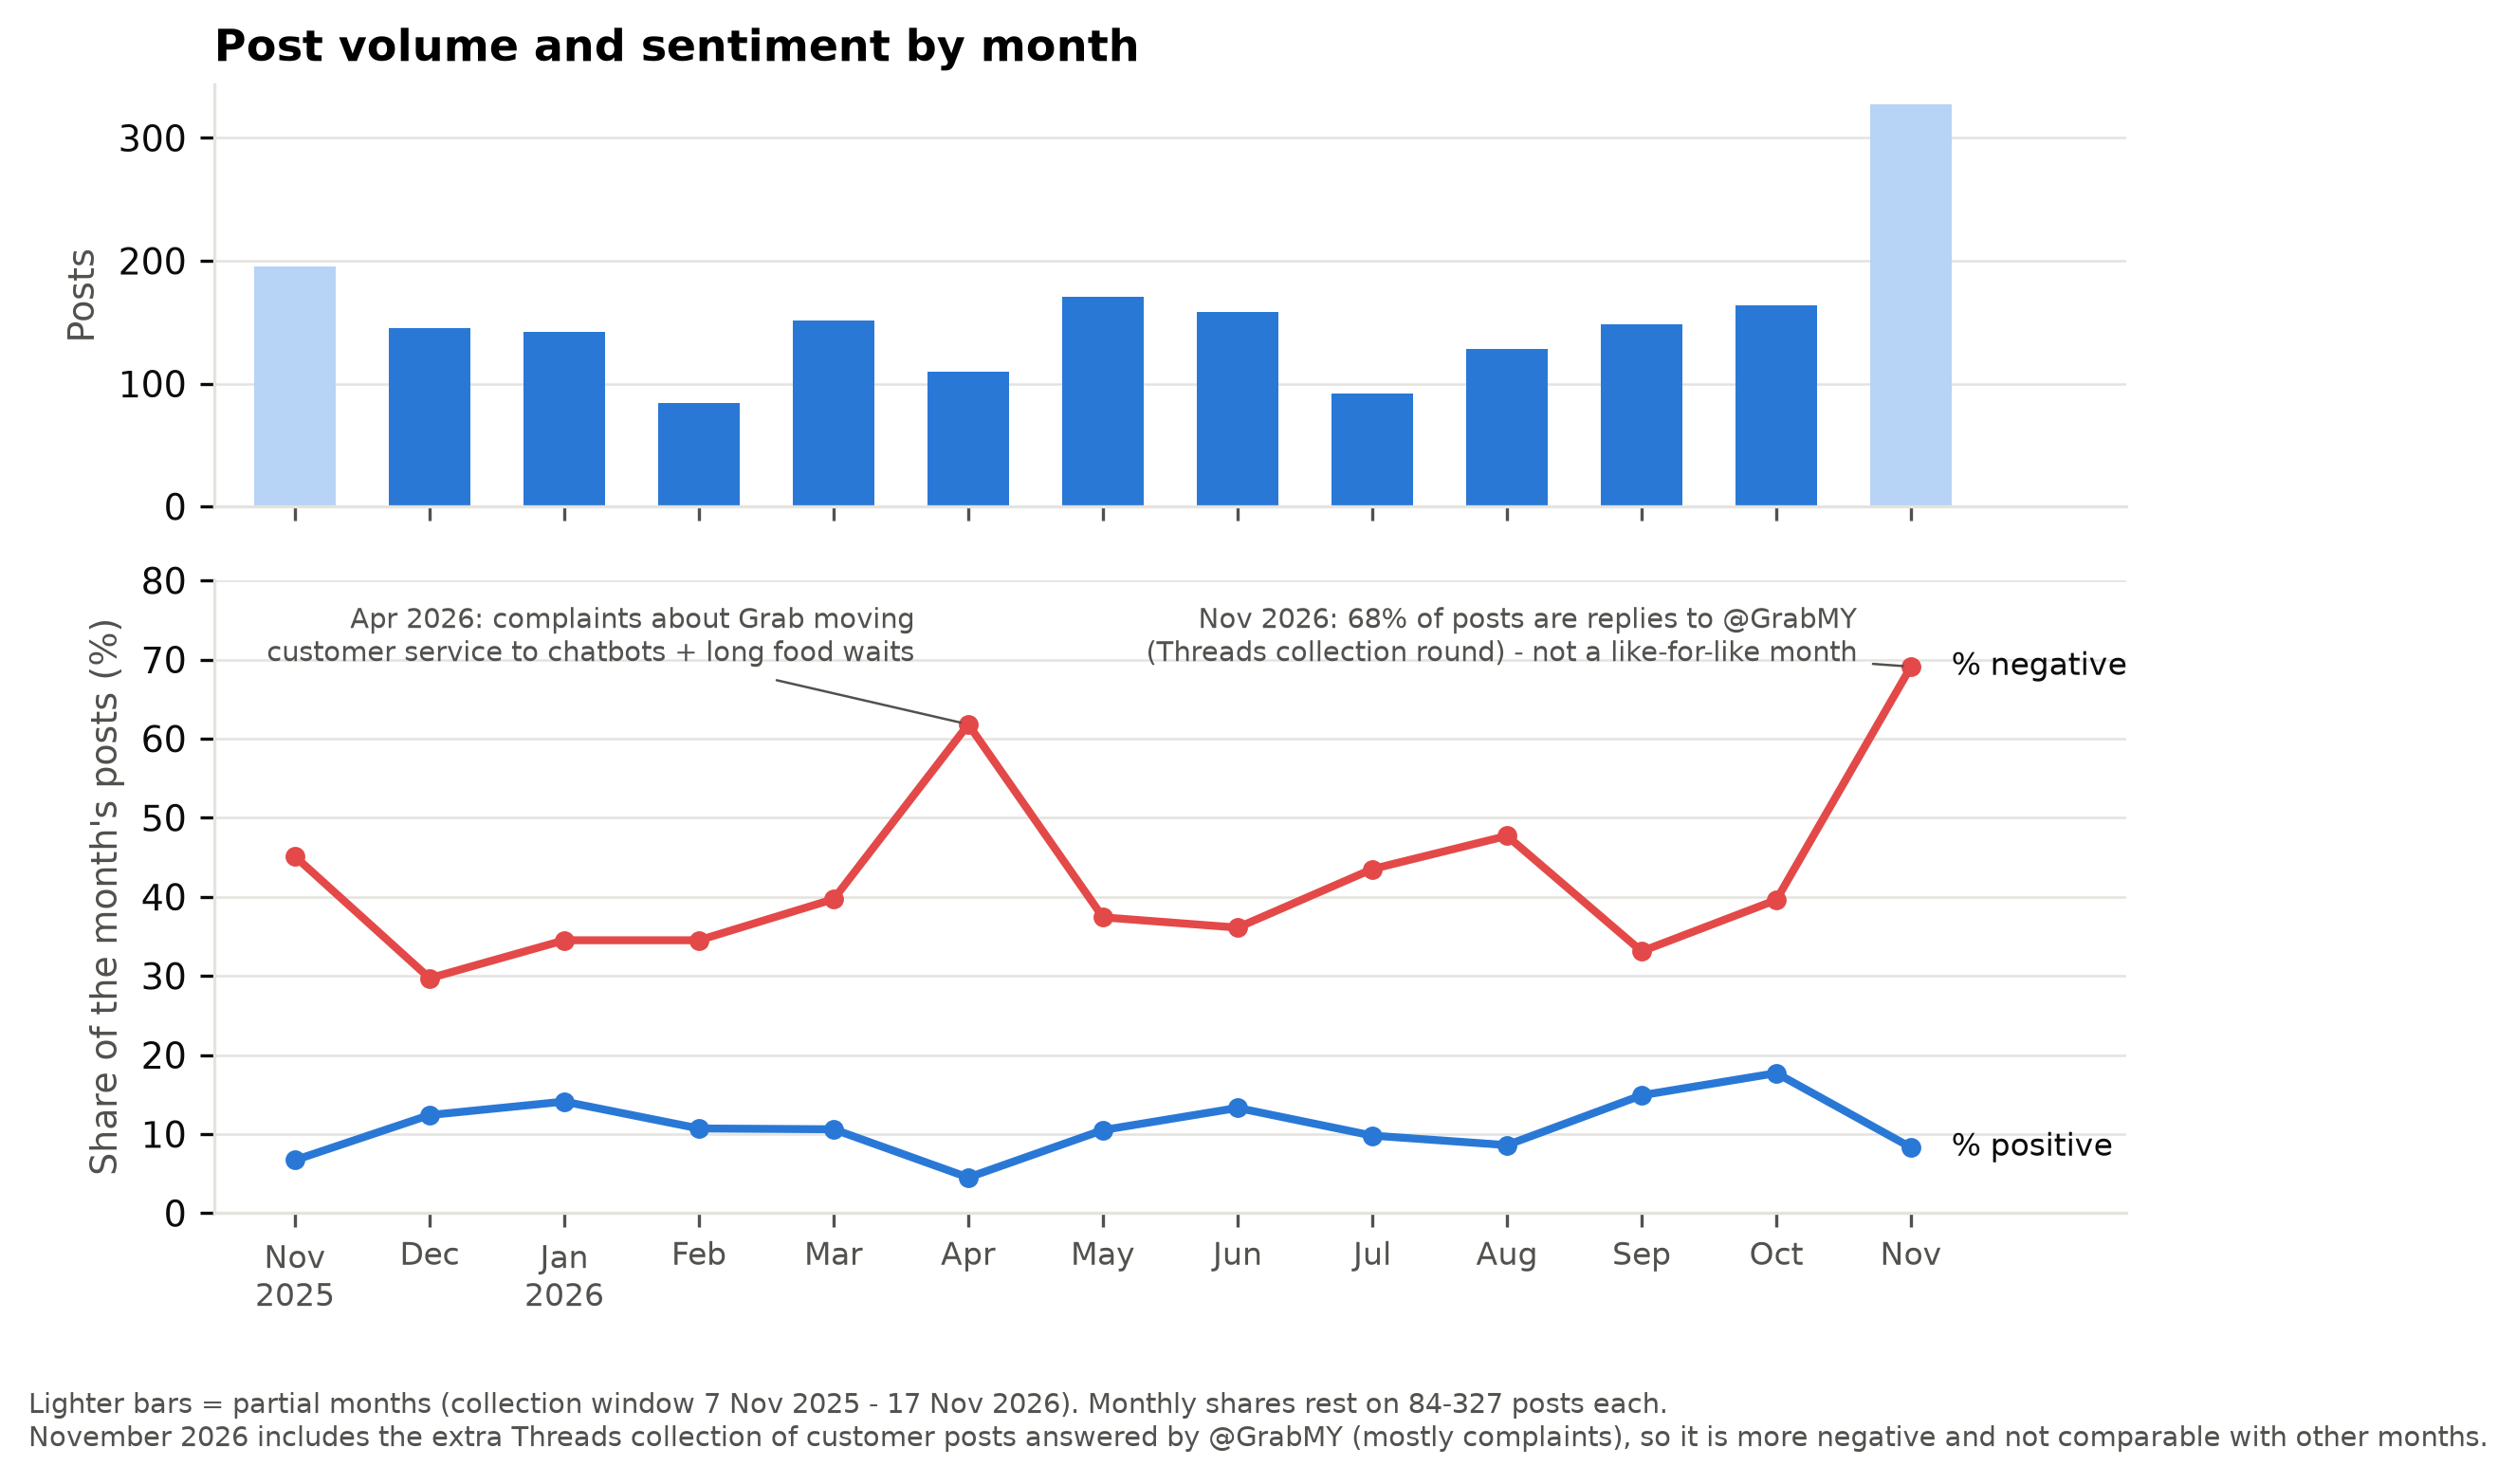

,month,n_posts,n_negative,n_neutral,n_positive,pct_negative,pct_neutral,pct_positive,net_sentiment,note
0,2025-11,195,88,94,13,45.1,48.2,6.7,-38.5,partial month
1,2025-12,145,43,84,18,29.7,57.9,12.4,-17.2,
2,2026-01,142,49,73,20,34.5,51.4,14.1,-20.4,
3,2026-02,84,29,46,9,34.5,54.8,10.7,-23.8,
4,2026-03,151,60,75,16,39.7,49.7,10.6,-29.1,
5,2026-04,110,68,37,5,61.8,33.6,4.5,-57.3,
6,2026-05,171,64,89,18,37.4,52.0,10.5,-26.9,
7,2026-06,158,57,80,21,36.1,50.6,13.3,-22.8,
8,2026-07,92,40,43,9,43.5,46.7,9.8,-33.7,
9,2026-08,128,61,56,11,47.7,43.8,8.6,-39.1,


In [5]:
show("fig04_sentiment_by_month"); display(T["tab04_sentiment_by_month"])

## 5. Topics: what people talk about, and how they feel about it
Topics are found with a **keyword dictionary in English and Malay**. Every tag can be explained, for example "mahal" leads to *Price*.
One post can touch several topics. The keyword lists are in `src/findings.py` (`TOPICS`).

In [6]:
for t, words in TOPICS.items():
    print(f"{t:45s} {', '.join(w.replace(chr(92), '') for w in words[:10])} ...")

Price, fares & fees                           prices?, pricing, fares?, mahal, expensive, overpriced, pricey, surgew*, cheap(?:er|est)?, murah ...
Drivers & rides (GrabCar)                     drivers?, rides?, grab ?car, car, pick ?up, drop ?off, route, trips?, airport, klia ...
Food & delivery (GrabFood/Mart/Express)       grab ?food, food, deliver(?:y|ies|ed)?, orders?, ordered, riders?, makanan, restaurants?, merchants?, grab ?mart ...
Cancellations & waiting time                  cancelw*, wait(?:ing|ed)?, tunggu, lambat, late, slow, lama, delay(?:ed)?, no drivers?, lembab ...
Customer service & refunds                    customer service, customer support, support, cs, refunds?, refunded, complainw*, report(?:ed)?, tickets?, responw* ...
App & technology (incl. AI)                   apps?, update[sd]?, bugs?, glitchw*, crashw*, error, maps?, gps, log ?in, accounts? ...
Payments & GrabPay                            grab ?pay, e-?wallet, wallet, payments?, paylater, pay ?later, car

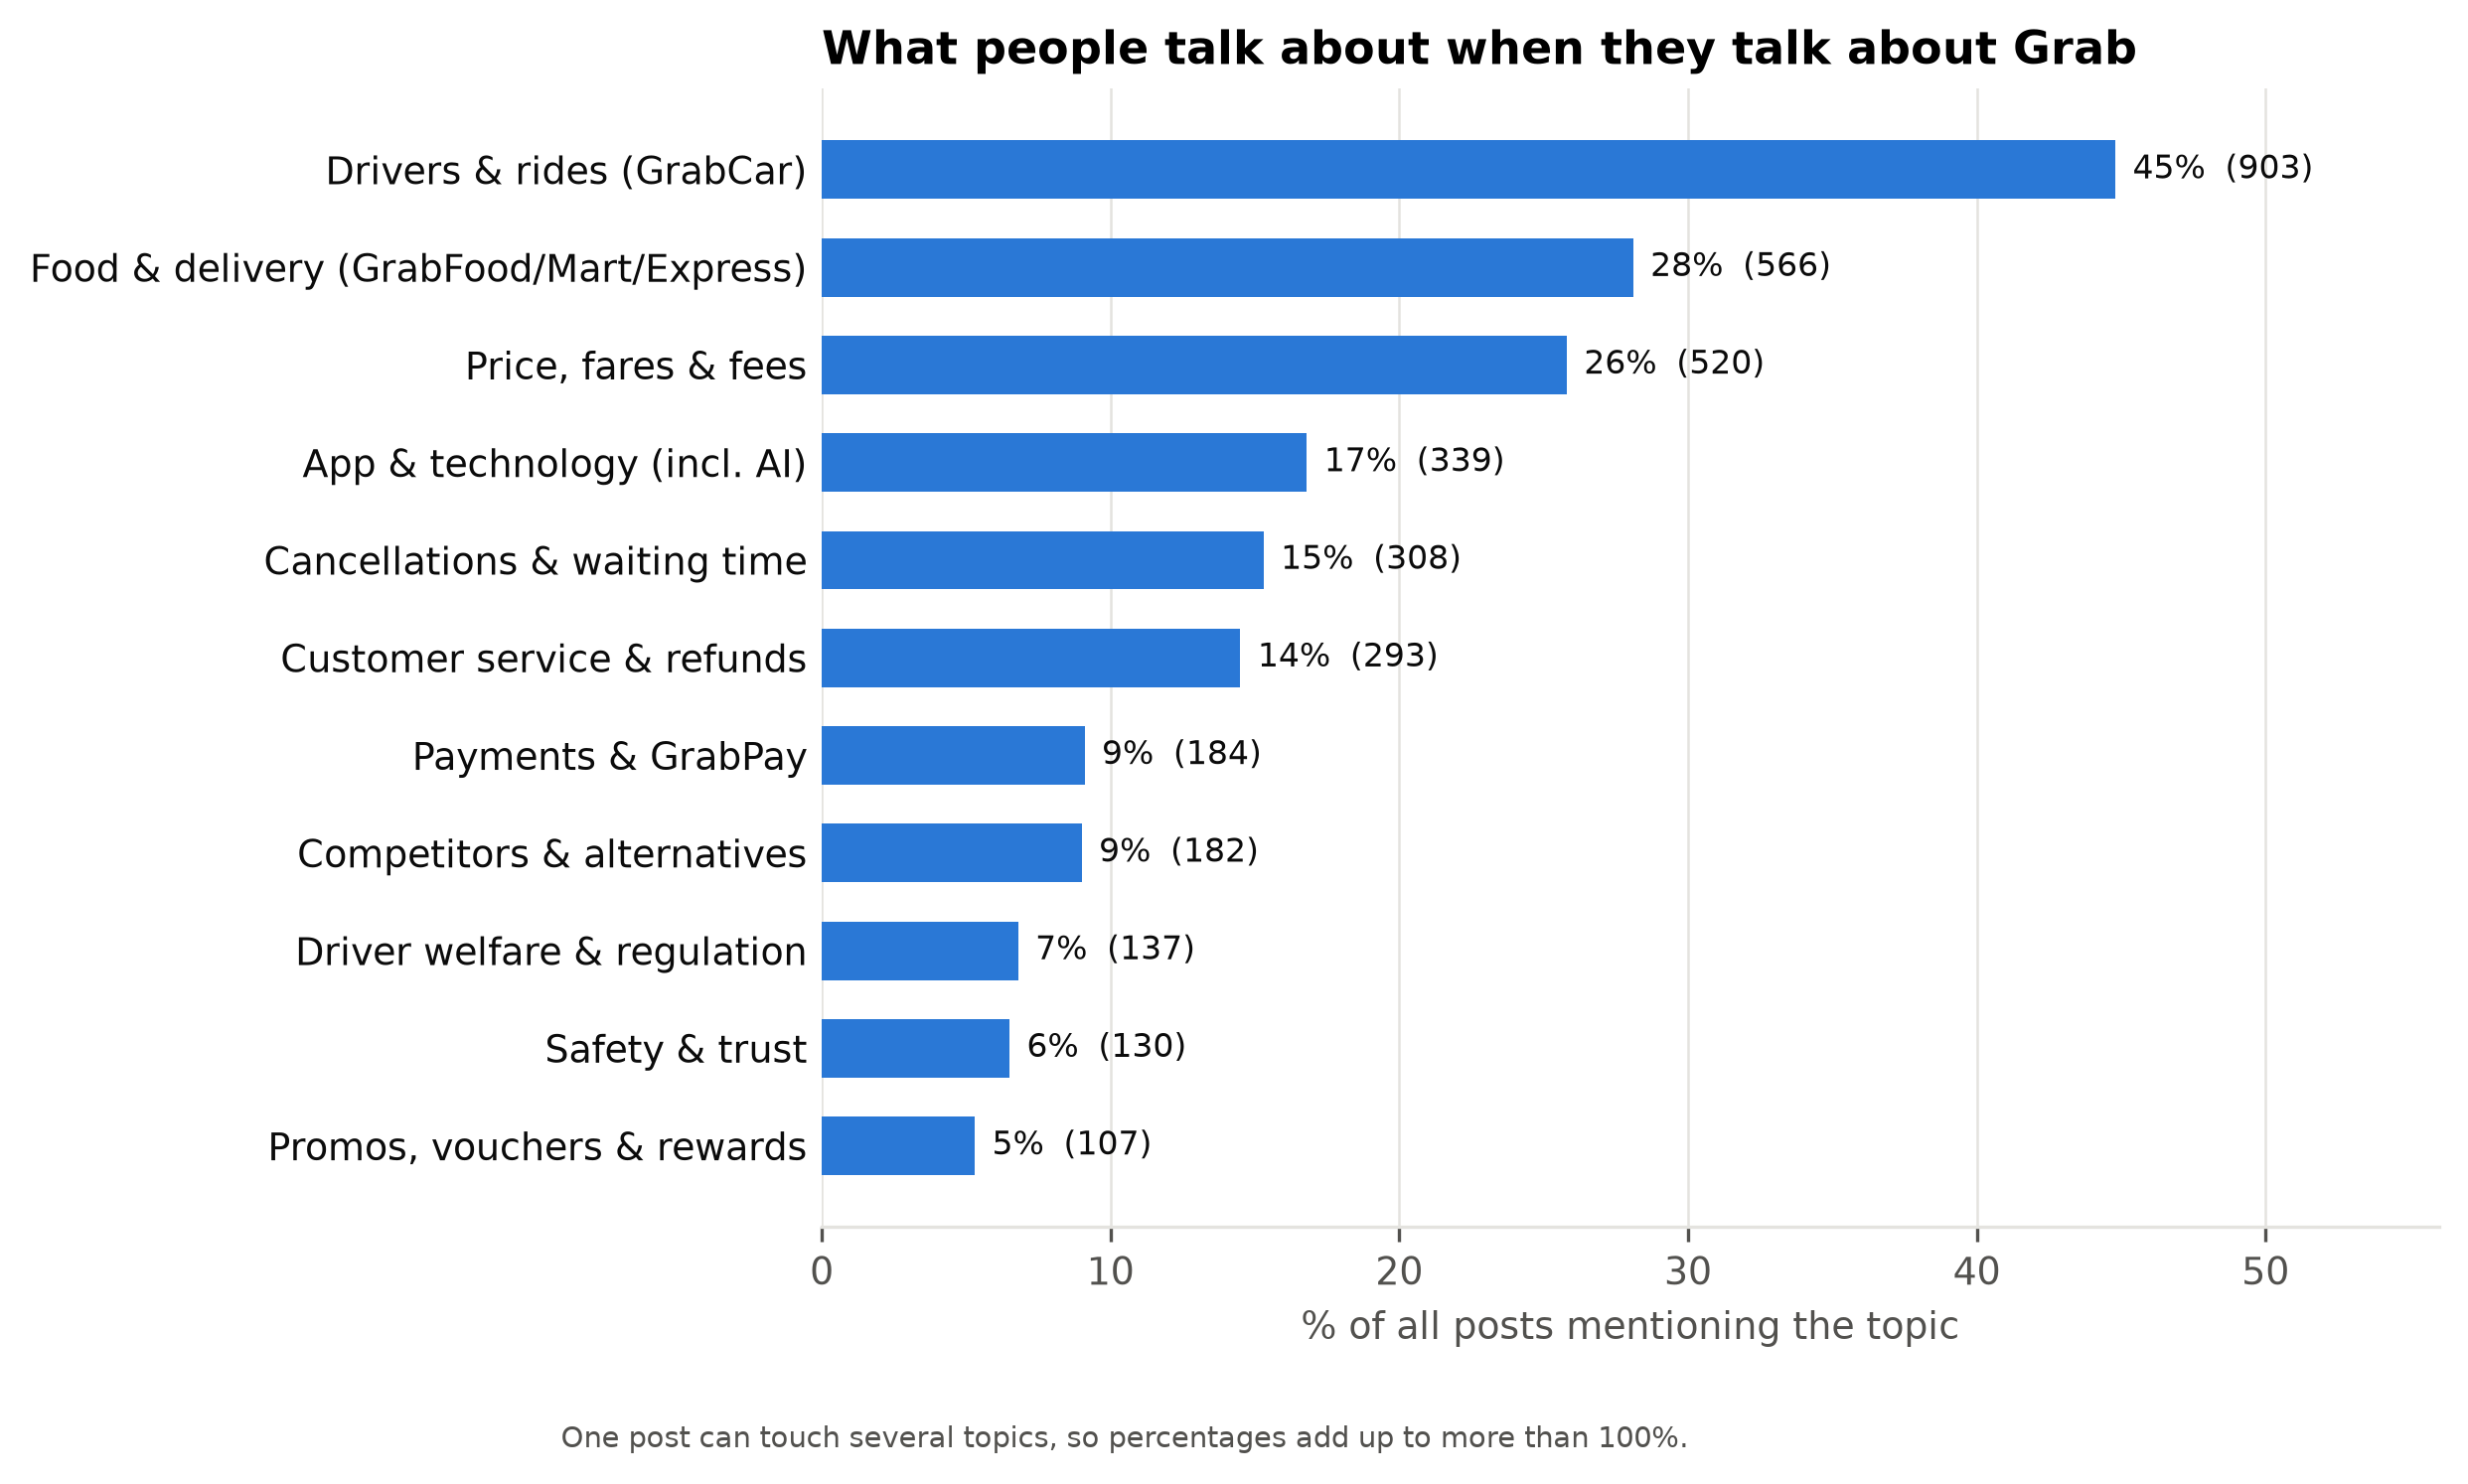

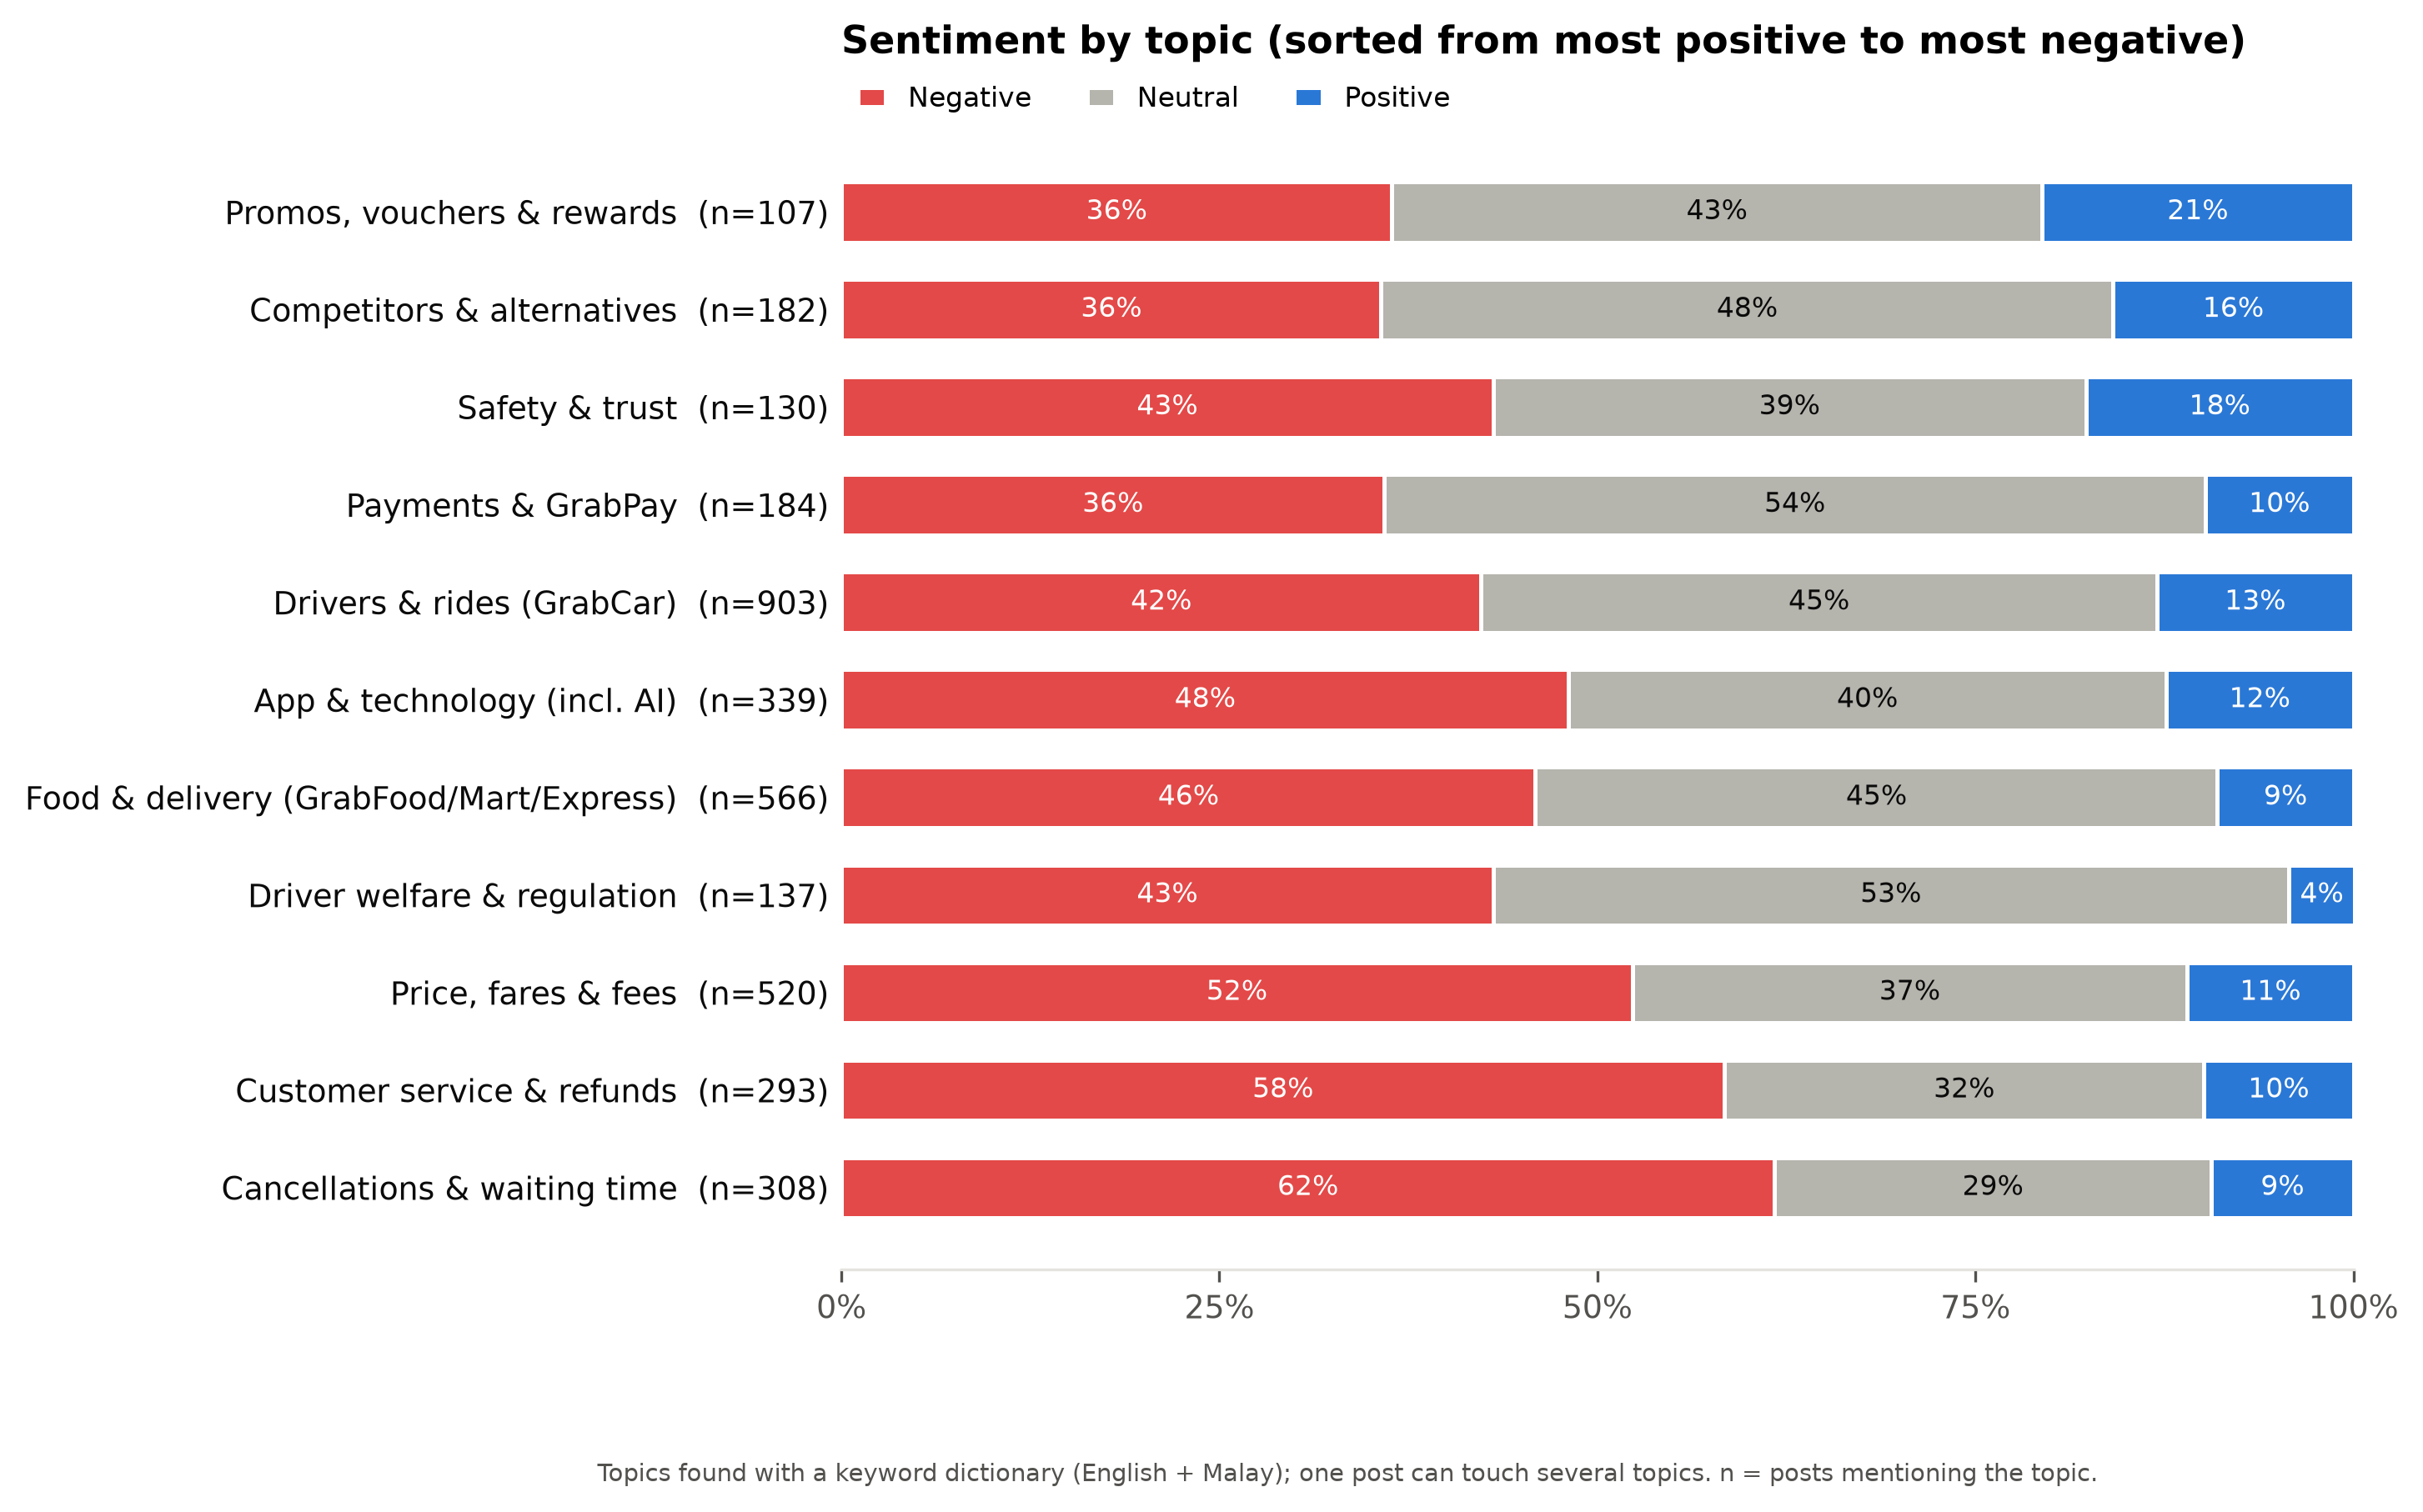

,topic,n_posts,pct_of_all_posts,pct_negative,pct_neutral,pct_positive,net_sentiment,pct_malay_or_mixed,example_negative,example_positive
0,"Price, fares & fees",520,25.8,52.3,36.7,11.0,-41.3,38.3,[Threads] @grabmy but what you Will do for Puspa..? Only taking credits for your company.? After that still continue giving Rubbish Fare...,"[Reddit] Okay, yup better to take Grab so the price is fixed"
1,Drivers & rides (GrabCar),903,44.8,42.3,44.7,13.0,-29.3,29.9,[X (Twitter)] @user @GrabMY can you don't be so snakey & on saver job for drivers WHO DIS NOT ON SAVER BUTTON..! @user @user can you loo...,"[Threads] Haritu stay dekat Cameron Highlands pastu mom not feeling well, terus book grab direct to Penang. Alhamdulillah ada juga yg te..."
2,Food & delivery (GrabFood/Mart/Express),566,28.1,45.9,45.1,9.0,-36.9,45.6,"[X (Twitter)] So @GrabMY notified that it picked up my order from KFC and its otw but a few minutes later it said ""Penghantaran dibatalk...",[X (Twitter)] LAWAK LA AKU TGK LIVE GRABFOOD SEMALAM [loudly crying face] [loudly crying face] [loudly crying face] tak berhenti gelak s...
3,Cancellations & waiting time,308,15.3,61.7,28.9,9.4,-52.3,35.4,[X (Twitter)] apa yg babi sangat grab ni dah dekat dengan i pastu dia cancel ee,"[X (Twitter)] Whoaa power abang grab ni, macam tahu je aku dah lambat, dia bawa jalan shortcut takde jem URL"
4,Customer service & refunds,293,14.5,58.4,31.7,9.9,-48.5,23.2,[X (Twitter)] @GrabMY so how ??? Still no response after i contact thru IGs. URL,"[X (Twitter)] @GrabMY your service is seriously phenomenal. Time and time again, you assist me with issues and I really appreciate the t..."
5,App & technology (incl. AI),339,16.8,48.1,39.5,12.4,-35.7,21.2,[Threads] @user.ai terjemahkan dalam bahasa melayu. Mane nak paham tulisan cacing kerawit ni. @grabmy jarang tak buat hal [face with rol...,[Reddit] Use grab app . It wiill save you both time and money
6,Payments & GrabPay,184,9.1,35.9,54.3,9.8,-26.1,35.3,[Reddit] You should blame Grab for allowing payment in cash. This doesn't make sense in this day and age.,"[Reddit] Some game channel also dont accept grabpay. Old time can, now cannot. Dont know why. I like the grab coins benefit too."
7,"Promos, vouchers & rewards",107,5.3,36.4,43.0,20.6,-15.9,29.9,"[Threads] No problem bro... Kasi share je... Kot2 nnt dh Viral baru si @grabmy nk reached out bagi solution, or communication channel......","[X (Twitter)] @GrabMY thanks for the offers bro, i can't lie i am kinda broke [weary face] URL"
8,Safety & trust,130,6.5,43.1,39.2,17.7,-25.4,23.8,[X (Twitter)] @user @GrabMY sepatah dua kata? I dont feel happy or even safe to have samseng or Sarip Dol hntrkn mknn. Pekerja hnya jlnk...,[Reddit] Taxi drivers are scammy but grab drivers are pretty great since everything go through the apps.
9,Driver welfare & regulation,137,6.8,43.1,52.6,4.4,-38.7,27.7,"[Reddit] Exactly, i really don't know what justify that most of the earning goes to Grab. It is all greed/anti consumer imo.","[X (Twitter)] @user @user Is there any law that says businesses must accept cash? If not, why make this an issue when there is no issue?..."


In [7]:
show("fig06_topic_volume"); show("fig05_sentiment_by_topic")
display(T["tab05_topic_summary"].drop(columns=["keywords_used"]))

**Topic mix by platform** (% of each platform's posts that touch the topic):

In [8]:
display(T["tab06_topic_by_platform"])

,topic,X (Twitter),Reddit,Threads,TikTok,Facebook
0,"Price, fares & fees",27.0,24.3,26.3,15.7,32.3
1,Drivers & rides (GrabCar),44.4,49.3,39.3,21.6,38.7
2,Food & delivery (GrabFood/Mart/Express),36.9,16.9,24.6,21.6,16.1
3,Cancellations & waiting time,14.0,16.9,20.1,2.0,9.7
4,Customer service & refunds,10.4,17.8,24.1,9.8,22.6
5,App & technology (incl. AI),14.9,16.1,29.0,11.8,16.1
6,Payments & GrabPay,8.4,7.5,17.9,2.0,16.1
7,"Promos, vouchers & rewards",5.3,5.3,6.2,0.0,6.5
8,Safety & trust,6.9,6.8,4.5,5.9,0.0
9,Driver welfare & regulation,8.3,5.9,4.5,0.0,3.2


**Cross-check with an unsupervised topic model (NMF).** The computer groups words that appear together, with no keyword list.
It finds the same main themes: rides/airport, drivers, food delivery, riders, cancellations, price ("mahal", "harga") and safety/police reports.
That agreement supports the keyword topics.

In [9]:
display(T["tab07_nmf_topics_crosscheck"])

,nmf_topic,top_words,n_posts,pct_negative,pct_neutral,pct_positive
2,3,"time, kl, ride, airport, day, car, hour, use, need, klia",683,36.6,47.4,16.0
0,1,"driver, passenger, naik, dapat, hailing, did, ride, customer, car, road",323,49.8,38.4,11.8
1,2,"order, grabfood, food, delivery, foodpanda, shopeefood, ordered, restaurant, voucher, eats",209,44.5,48.3,7.2
6,7,"malaysia, app, singapore, bernamanews, hailing, rakan, ai, company, star, malaysian",205,23.4,64.9,11.7
4,5,"rider, kena, lain, makanan, semua, memang, dapat, bagi, customer, kerja",184,52.2,42.4,5.4
7,8,"cancel, customer, kena, tunggu, accept, order, want, sampai, pickup, lama",154,68.2,29.9,1.9
3,4,"mahal, naik, harga, beli, balik, sampai, fare, kereta, keluar, kerja",151,64.9,28.5,6.6
5,6,"report, police, want, jpj, action, safety, did, kpdn, assault, said",89,46.1,46.1,7.9


## 6. Talking TO Grab vs talking ABOUT Grab
Posts that tag @GrabMY, reply to it, or comment under Grab's own posts are far more negative. People use Grab's social accounts as a complaints desk.

In [10]:
display(T["tab11_talking_to_vs_about_grab"])

,audience,n_posts,n_negative,n_neutral,n_positive,pct_negative,pct_neutral,pct_positive,net_sentiment
0,Talking ABOUT Grab,1467,514,783,170,35.0,53.4,11.6,-23.4
1,Talking TO Grab (tag / reply / comment),548,385,115,48,70.3,21.0,8.8,-61.5
2,All posts,2015,899,898,218,44.6,44.6,10.8,-33.8


## 7. Words most typical of each sentiment

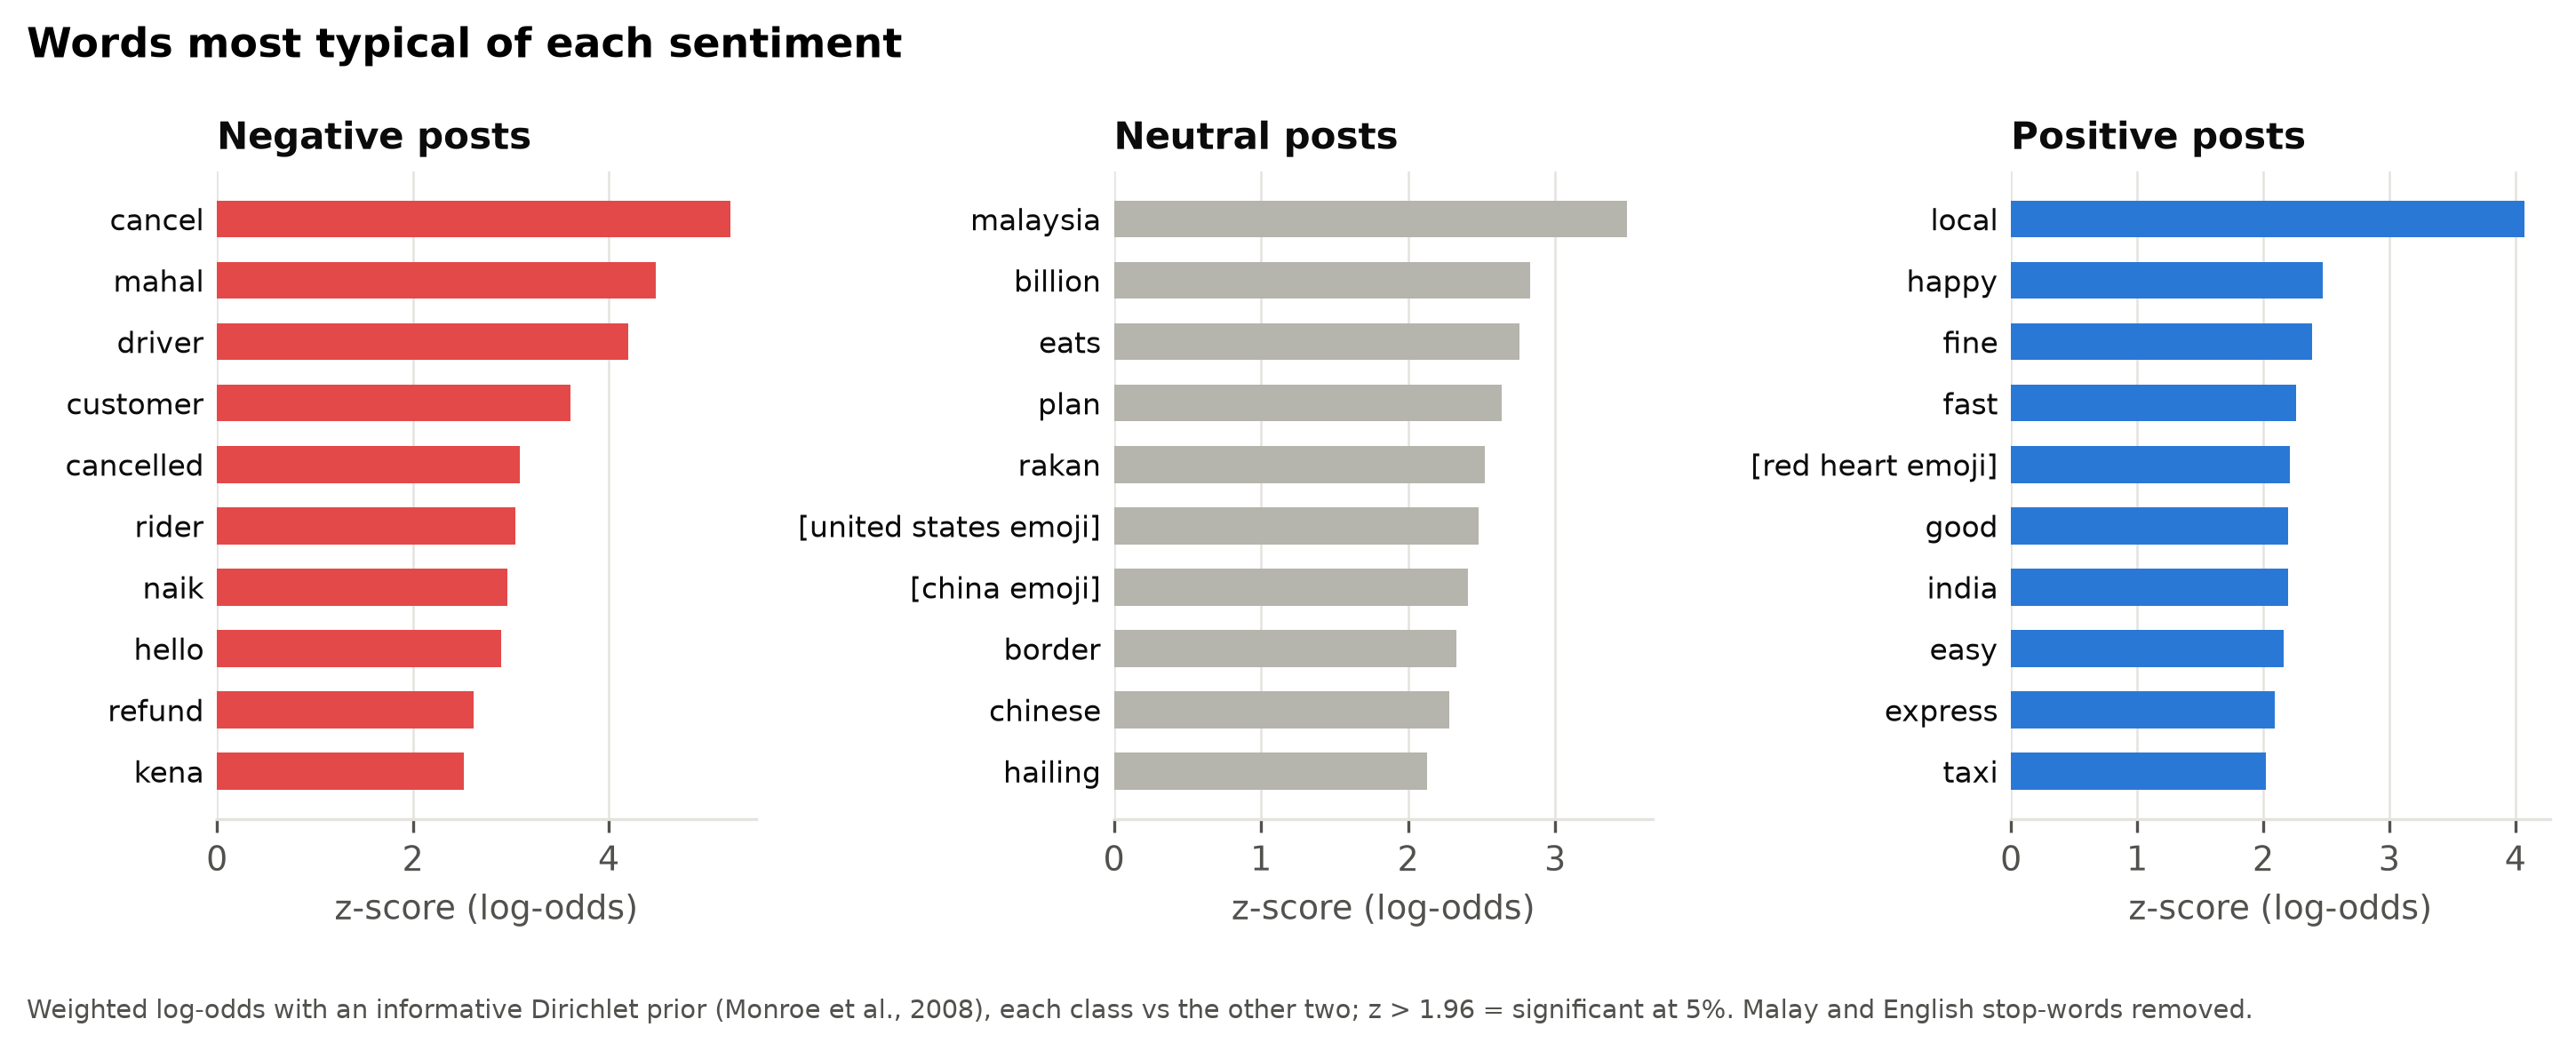

In [11]:
show("fig07_distinctive_words")

## 8. Engagement (likes and replies) by sentiment

In [12]:
display(T["tab10_engagement_by_sentiment"])

,platform,sentiment,n_posts,median_likes,mean_likes,median_replies
0,Facebook,negative,27,0.0,0.3,1.0
1,Facebook,neutral,3,0.0,0.0,2.0
2,Facebook,positive,1,0.0,0.0,NaN
3,Reddit,negative,242,3.0,22.8,18.0
4,Reddit,neutral,370,3.0,18.0,13.5
5,Reddit,positive,64,3.0,14.5,14.0
6,Threads,negative,164,1.0,210.0,2.0
7,Threads,neutral,42,3.5,153.4,3.0
8,Threads,positive,18,5.0,81.1,1.0
9,TikTok,negative,30,0.0,2.6,0.0


## 9. Sentiment-model comparison (from notebook 06)

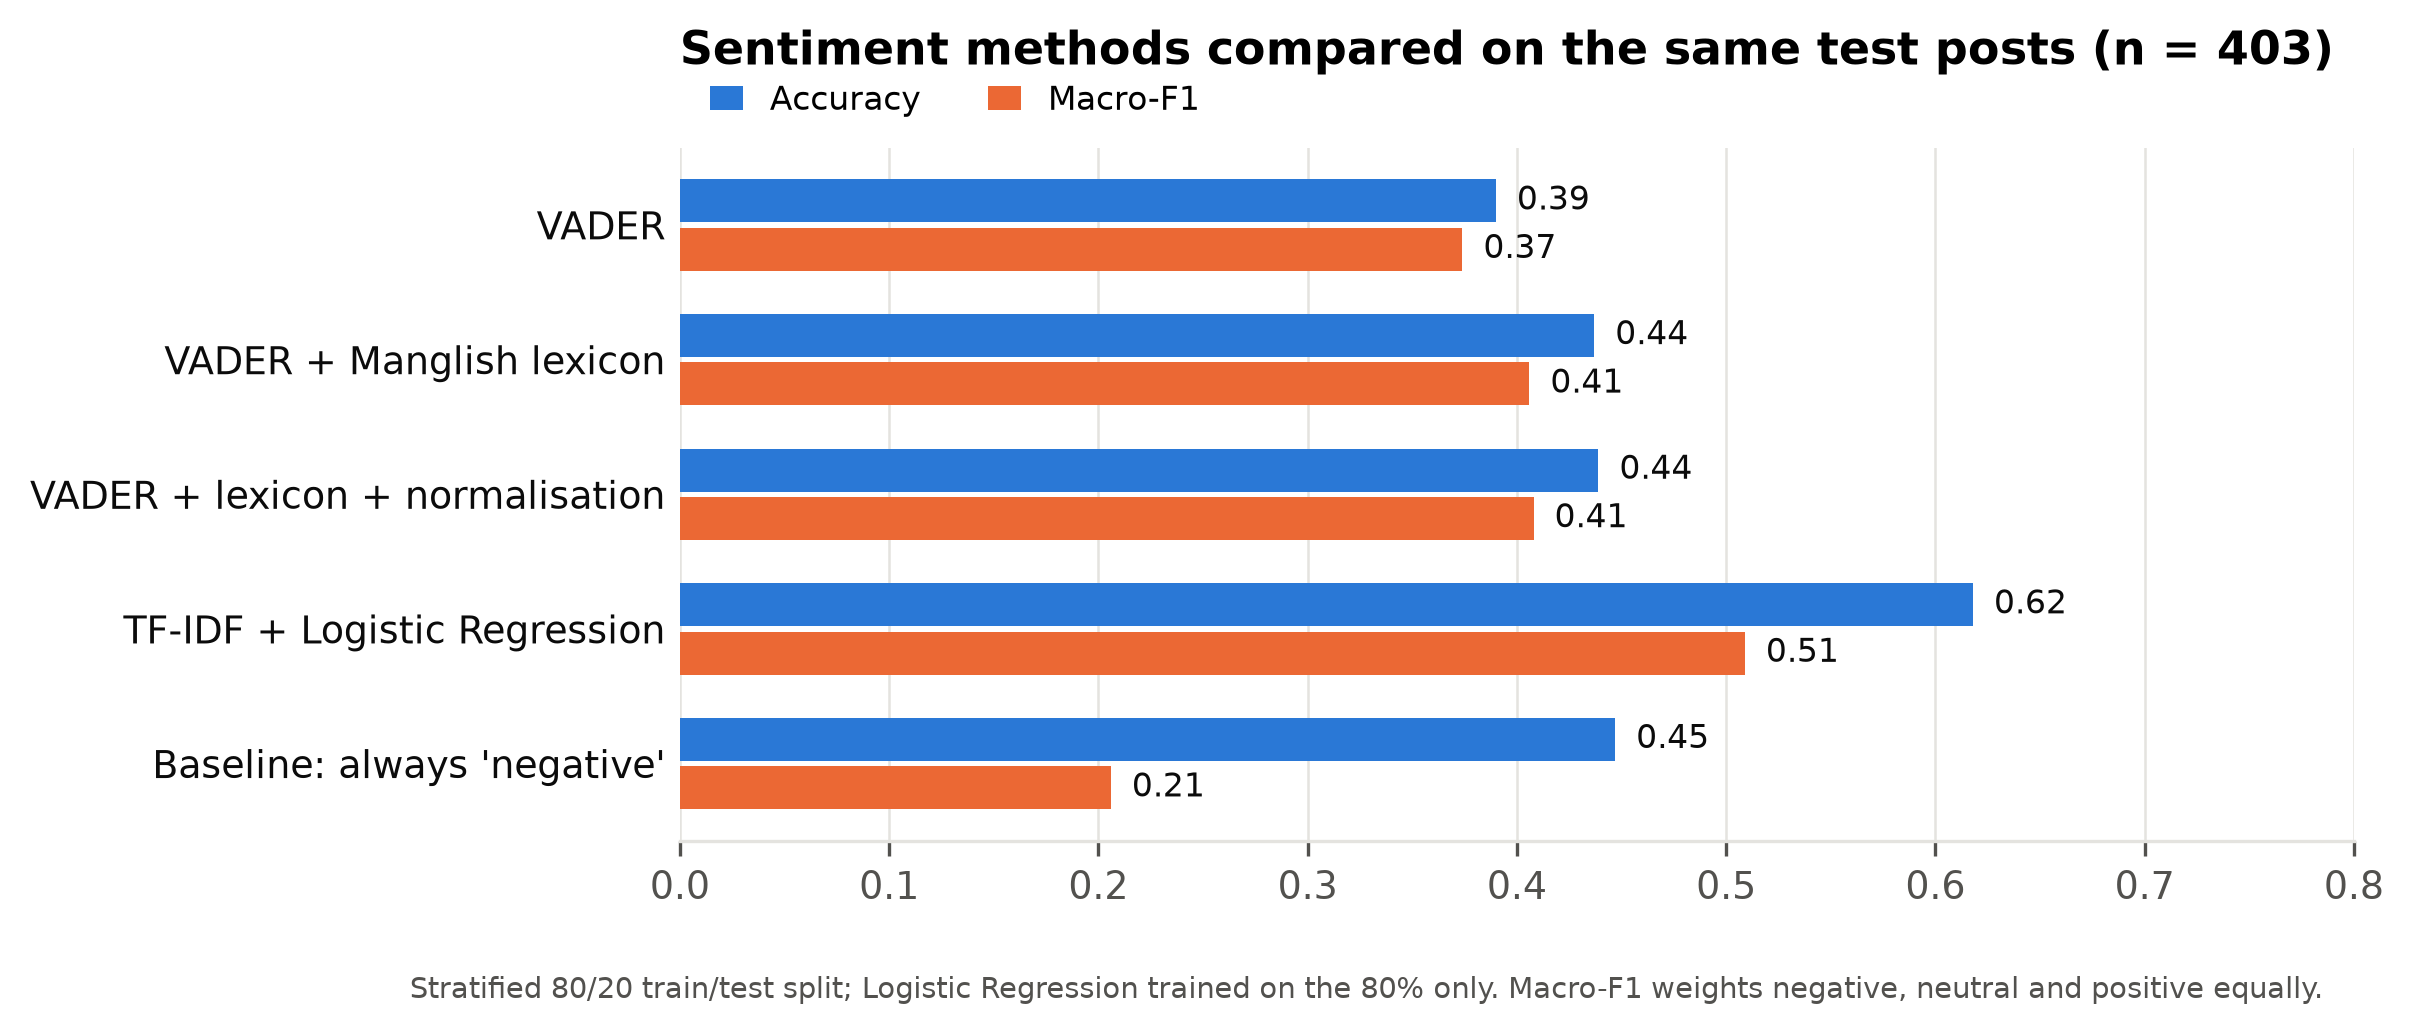

,method,evaluated_on,n,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
0,(a) VADER,test (20%),403,0.390,0.374,0.409,0.516,0.336,0.272
1,(b) VADER + Manglish lexicon,test (20%),403,0.437,0.406,0.451,0.614,0.331,0.275
2,(c) VADER + lexicon + normalisation,test (20%),403,0.439,0.408,0.453,0.616,0.331,0.277
3,(d) TF-IDF + Logistic Regression,test (20%),403,0.618,0.509,0.615,0.690,0.640,0.195
4,Baseline: always 'negative',test (20%),403,0.447,0.206,0.276,0.617,0.000,0.000


In [13]:
show("fig08_model_comparison"); display(T["tab09_model_comparison"])

## 9b. How the methods differ in their sentiment distribution (all 2,015 posts)
How often does each method say *negative*, *neutral* or *positive*, compared with the labels?
* VADER needs no training, so it was run on every post.
* For Logistic Regression we used **5-fold cross-validation** (StratifiedKFold, shuffle, random_state = 42) with the same
  TF-IDF + LogReg pipeline as notebook 06. Every post is then predicted by a model that never saw it.

**Main point:** both VADER versions label about **39%** of posts positive, against **10.8%** in the labels. Logistic Regression's distribution (46 / 44 / 10%) is close to the labels.

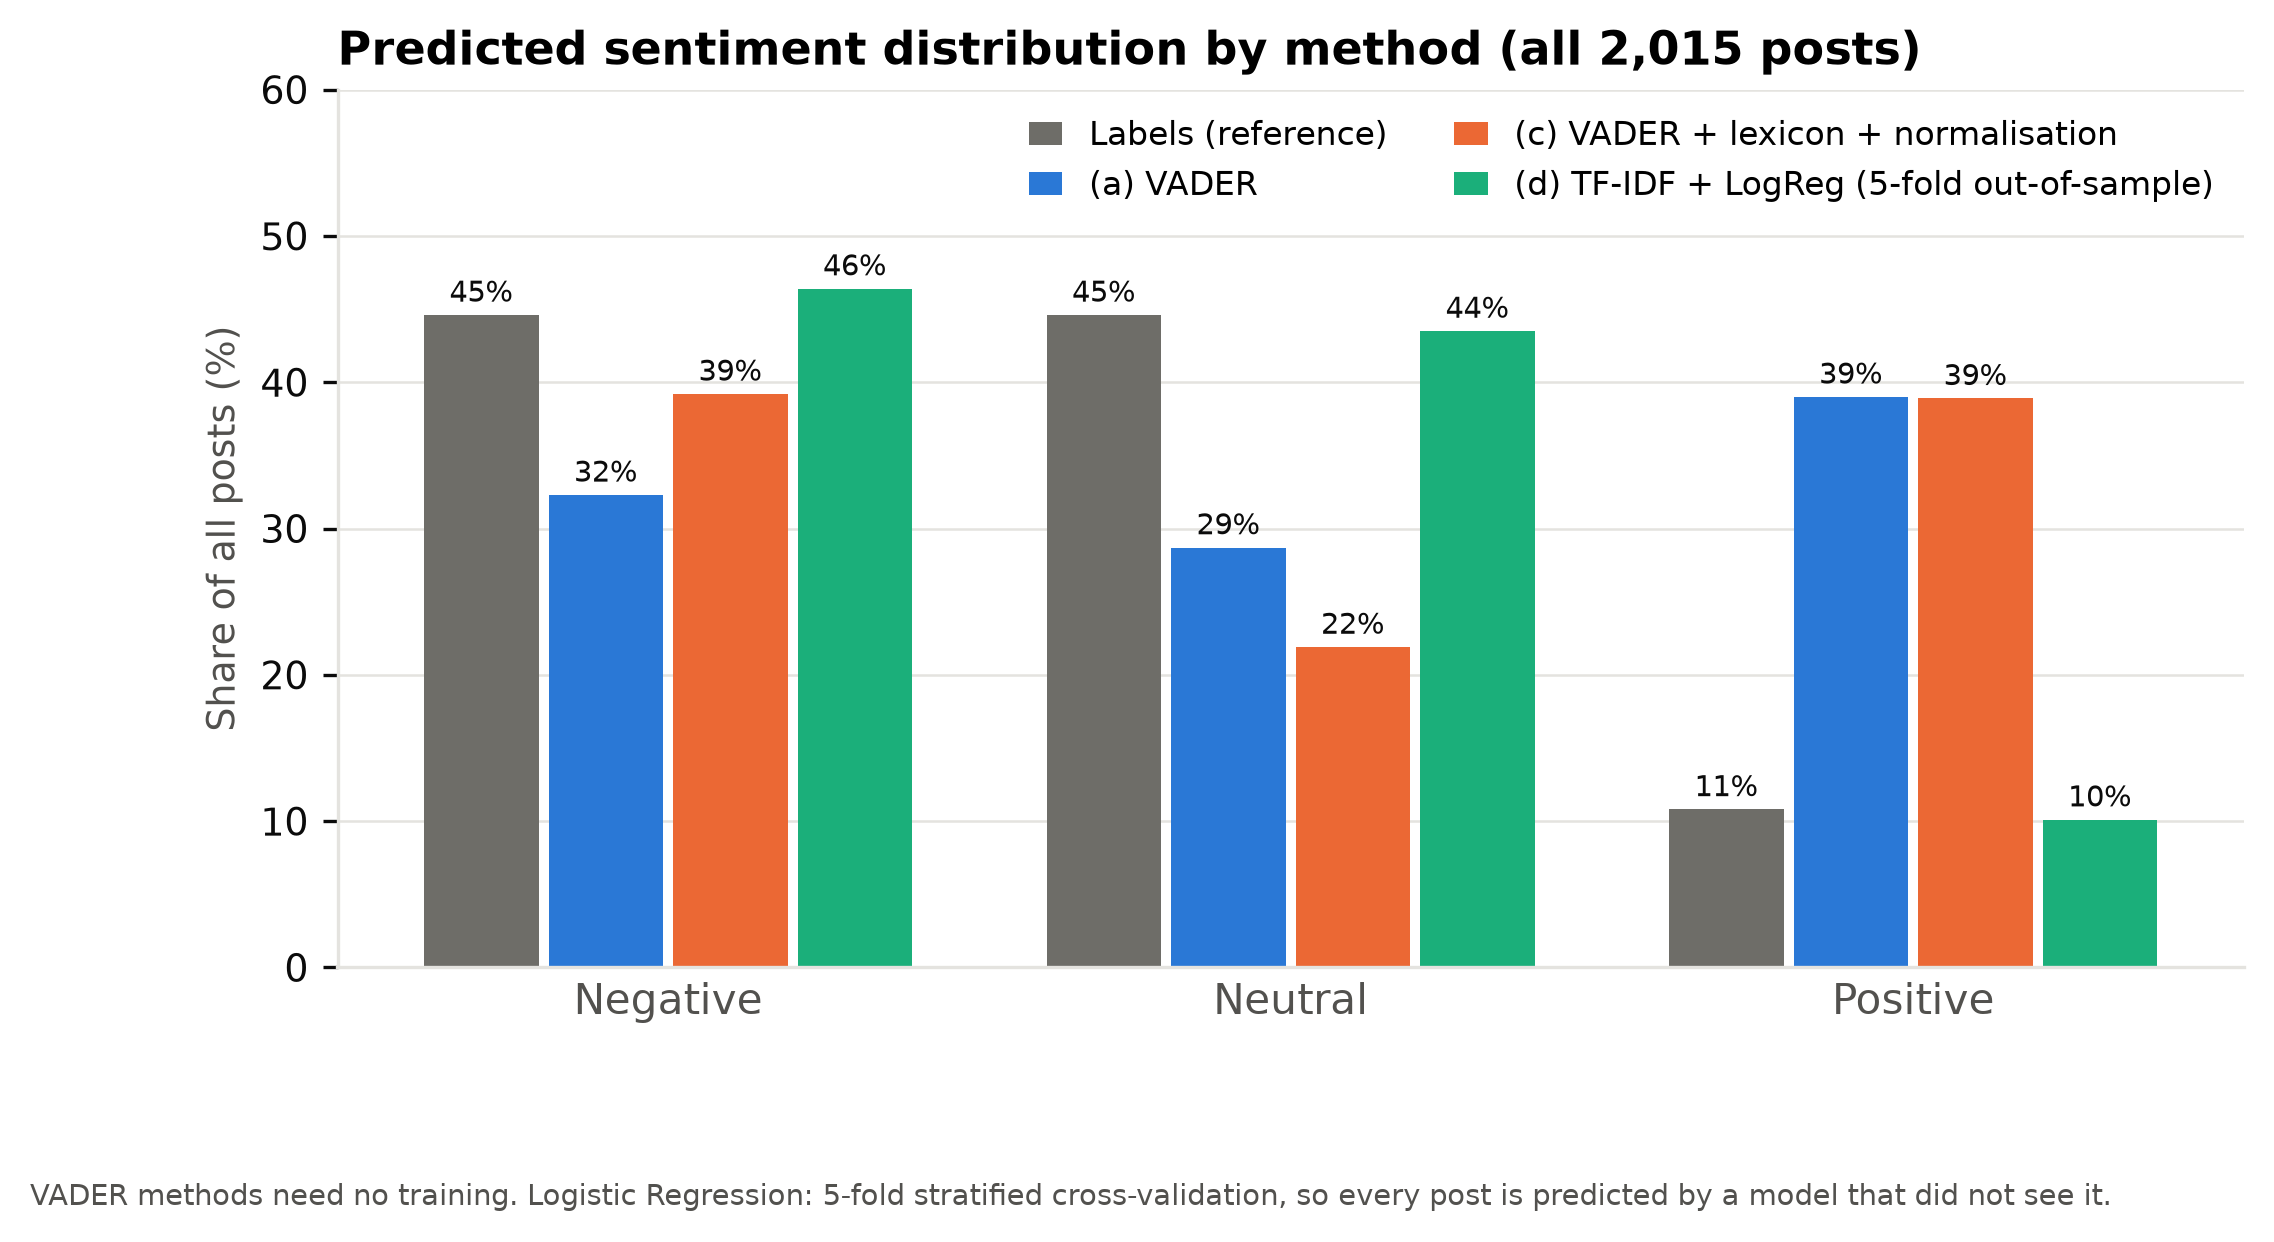

,method,n_posts,n_negative,n_neutral,n_positive,pct_negative,pct_neutral,pct_positive,agreement_with_labels_pct
0,Labels (reference),2015,899,898,218,44.6,44.6,10.8,100.0
1,(a) VADER,2015,651,579,785,32.3,28.7,39.0,39.8
2,(c) VADER + lexicon + normalisation,2015,790,442,783,39.2,21.9,38.9,43.3
3,(d) TF-IDF + LogReg (5-fold out-of-sample),2015,935,877,203,46.4,43.5,10.1,65.1


In [14]:
show("fig11_distribution_by_method")
display(T["tab14_distribution_by_method"])

**Why does VADER over-predict positive?** Five posts where plain VADER says *positive* but the label is *negative*.
* VADER scores single friendly words such as "legit", "hopefully", "proper", "help" and "honor", plus emojis.
* It cannot see complaints, sarcasm or negative context made of neutral words, for example "Rempit behaviour" or "didn't help I guess".
* Many complaints are written politely ("please", "thank you"), which VADER also counts as positive.

In [15]:
T["tab15_vader_positive_but_label_negative"]

,n_such_posts_in_dataset,post_id,platform,lang_group,true_label,a_vader_plain,vader_plain_compound,c_vader_lexicon_norm,vader_lexnorm_compound,text_clean
0,252,DfPgT8hk98e,threads,en,negative,positive,0.660,positive,0.660,"Is this giveaway legitimate, or are winners simply being left in the dark after submitting their personal information? [woman shrugging ..."
1,252,oix30hw,reddit,en,negative,positive,0.637,positive,0.637,Hopefully still have proper CS team for escalations. Sounds like not tho.
2,252,2063256762866933989,twitter,en,negative,positive,0.494,positive,0.494,@user @GrabMY Open a KPDN case. I did that for Shopee RM10 petrol campaign and KPDN officer legit took the case and had shopee to honor ...
3,252,nt9tkzl,reddit,en,negative,positive,0.296,positive,0.296,"I think i know this guy, and yeah Rempit behavior"
4,252,Dfo4bvanVAy,threads,mixed,negative,positive,0.510,positive,0.510,"Tahniah @grabmy, dapat rider rude dengan aku, i tried to lodge a proper report via your customer support, but it didn't help i guess? No..."


## 9c. Appendix file
All 2,015 posts with `post_id`, `platform`, `created_at`, `lang_group`, the anonymised text and the label are exported to
**`outputs/appendix_grab_posts_2015.csv`** for the report appendix. Personal @usernames were already replaced by `@user`.
The export checks that no personal handles are left, and it uses nothing from `data/raw/`.

In [16]:
appx = pd.read_csv(r["appendix"])
print(r["appendix"], appx.shape); appx.head(3)

outputs/appendix_grab_posts_2015.csv (2015, 6)


,post_id,platform,created_at,lang_group,text_anonymised,sentiment
0,no0tzeu,reddit,2025-11-10 00:05:57,en,"In Bangkok we also pay extra for tolls, but I pay cash so nothing gets added to the grab except the fee that I booked and agreed upon. I...",neutral
1,no1377v,reddit,2025-11-10 00:59:44,en,"2 years ago when my brother was grab driver, it was common knowledge among grab drivers that the app doesn't actually take tolls into ac...",negative
2,no1wjzz,reddit,2025-11-10 04:01:42,en,thats what the name suggest. it GRABs you by the ...,negative


## 10. Web analytics and app reviews (Part 1)
The website analysis and the Google Play / App Store reviews now live in their own folder:
**`website and app analysis/`** (notebook `website_and_app_analysis.ipynb` and `README.md`).

## Findings
The written findings, suggested figure captions and limitations are in **`outputs/FINDINGS.md`**.